In [1]:
import json
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import astropy.units as U
from galaxy_sidm.io import load_config
from galaxy_sidm.mock import CubeParams
from galaxy_sidm.mock.asymmetry import asymmetry_3d
from galaxy_sidm.mock.barolo import rings_file
from galaxy_sidm.mock.residuals import cube_residuals, pv_residuals
from galaxy_sidm.mock.tables import DISC_RULE, MODELS, flat_rings, gas_disc_sample

plt.rcParams.update({
    # paper font: bundled Computer Modern (cmr10) -- do NOT use usetex here
    "font.family": "serif",
    "font.serif": ["cmr10", "DejaVu Serif"],
    "mathtext.fontset": "cm",
    "axes.formatter.use_mathtext": True,
    "axes.unicode_minus": False,
    # legibility
    "axes.labelsize": 19,
    "axes.titlesize": 19,
    "xtick.labelsize": 15,
    "ytick.labelsize": 15,
    "legend.fontsize": 14,
    "xtick.direction": "in", "ytick.direction": "in",
    "xtick.top": True, "ytick.right": True,
    "xtick.major.size": 5.5, "ytick.major.size": 5.5,
})

cfg = load_config(None)
MARTINI = Path(cfg["paths"]["scratch_processed"]).parent / "martini"
PILOT = MARTINI.parent / "martini_pilot_disc_cut"
VERSIONS = {"current": MARTINI, "cut": PILOT}
colors = cfg["model_colors"]
markers = {"hand-picked": "*", "current only": "s", "new only": "^", "both": "o"}
KPC_PER_ARCSEC = (1 * U.arcsec * CubeParams().distance).to_value(U.kpc, U.dimensionless_angles())
flat_tol, retry_tol = 0.05, 0.10
workers = 8

In [2]:
#pilot galaxies and the current dividing line
pilot = pd.read_csv(PILOT / "pilot.csv")
gd = gas_disc_sample(cfg)
print(len(pilot), "galaxies:", pilot["group"].value_counts().to_dict())
print(f"line: mix = {gd.attrs['line_intercept']:.3f} + {gd.attrs['line_slope']:.3f} A_sq, "
      f"mix = {gd.attrs['a_pv']:.3f} PV + {1 - gd.attrs['a_pv']:.3f} cube res2")

50 galaxies: {'both': 26, 'current only': 10, 'new only': 10, 'hand-picked': 4}
line: mix = 13.579 + -14.267 A_sq, mix = 0.295 PV + 0.705 cube res2


In [3]:
#current and cut cube of every pilot galaxy, measured the same way, kept in comparison.csv
def measure(root, model, z, sub):
    g = root / f"z{z:g}" / model / f"gal_{sub:06d}"
    if not (g / "info.json").exists():
        return {"status": "no info.json", "note": ""}
    info = json.loads((g / "info.json").read_text())
    if (info.get("disc_cut") is not None) != (root == PILOT):
        raise ValueError(f"{g}: disc_cut = {info.get('disc_cut')}")
    row = {"status": "ok", "note": "", "noise_rms": info.get("cube_noise_rms", np.nan)}
    if "cube_npix" not in info:
        row["status"] = "no cube"
    elif info.get("bbarolo_3rings_rc") != 0:
        row["status"] = "3-ring fit failed"
    elif info.get("nradii") == 0:
        row["status"] = "no counted emission"
    elif info.get("bbarolo_rc") != 0:
        row["status"] = "no final fit"
    if row["status"] != "ok":
        return row
    vrot = np.loadtxt(rings_file(g / "bbarolo"), usecols=2, ndmin=1)
    used, rule = flat_rings(vrot, flat_tol, retry_tol)
    row.update(emission_end_kpc=max(r for r in info["pv_emission_end_arcsec"] if r is not None) * KPC_PER_ARCSEC,
               n_rings=info["nradii"], hole_rings=len(info["hole_rings_arcsec"]),
               v_flat=float(vrot[used].mean()) if rule is not None else np.nan, flat_rule=rule,
               V_over_sigma=info["V_over_sigma"],
               mix=gd.attrs["a_pv"] * pv_residuals(g)[1] + (1 - gd.attrs["a_pv"]) * cube_residuals(g)[1])
    try:
        row["A_sq"] = asymmetry_3d(g).A_sq
    except (OSError, ValueError, KeyError) as e:
        row.update(A_sq=np.nan, note=f"A_sq: {e}")
    return row


key = ["group", "model", "z", "subID"]
table = PILOT / "comparison.csv"
if table.exists():
    long = pd.read_csv(table).fillna({"note": ""})
    print(f"read {table} (delete it to measure again)")
else:
    tasks = [(v, k) for k in pilot[key].itertuples(index=False) for v in VERSIONS]
    with ThreadPoolExecutor(max_workers=workers) as ex:
        long = pd.DataFrame(list(ex.map(
            lambda t: {"version": t[0], **dict(zip(key, t[1])), **measure(VERSIONS[t[0]], *t[1][1:])}, tasks)))
    long.to_csv(table, index=False)
    print(f"wrote {table}")
wide = long.pivot(index=key, columns="version")
print(pd.crosstab(long["status"], long["version"]))
issues = long[(long["status"] != "ok") | (long["note"] != "")]
if len(issues):
    print(issues[["version"] + key + ["status", "note"]].to_string(index=False))
ref = pilot.set_index(key).reindex(wide.index)
for q in ("A_sq", "mix"):
    print(f"largest |recomputed - table| of the current cubes, {q}: "
          f"{np.nanmax(np.abs(wide[(q, 'current')].astype(float) - ref[q])):.2e}")
wide[["status", "emission_end_kpc", "n_rings", "hole_rings", "v_flat", "flat_rule", "V_over_sigma", "noise_rms",
      "A_sq", "mix"]]

read /scratch/s4636708/aida/derived/martini_pilot_disc_cut/comparison.csv (delete it to measure again)
version  current  cut
status               
ok            50   50
largest |recomputed - table| of the current cubes, A_sq: 0.00e+00
largest |recomputed - table| of the current cubes, mix: 8.88e-16


status     emission_end_kpc            n_rings  \
version                      current cut          current        cut current   
group        model z   subID                                                   
both         CDM   0.5 72215      ok  ok        16.362462  14.908021      23   
                       78273      ok  ok        18.544123  18.544123      26   
                       85792      ok  ok        13.089969   9.817477      18   
                       94189      ok  ok        14.180800  10.665901      20   
                   1.0 80815      ok  ok         4.605730   4.242120       7   
                   2.0 13664      ok  ok         6.666188   5.938968       9   
             SIDM1 0.5 38640      ok  ok        27.755583  26.785956      27   
                       54545      ok  ok        45.693689  33.088534      58   
                       66549      ok  ok        44.360452  24.604294      53   
                       83903      ok  ok        11.877935  11.514325      17   
                   1.0 57996      ok  ok         9.211460   9.211460      13   
                       63325      ok  ok        11.756732  11.756732      16   
                       69105      ok  ok         5.575357   5.575357       8   
                   2.0 15416      ok  ok        11.150715   8.241833      16   
                       30408      ok  ok         4.120916   3.999713       6   
                       31878      ok  ok        11.877935  11.877935      17   
                       40566      ok  ok         4.848137   4.726933       7   
                   3.0 14303      ok  ok         2.908882   2.908882       4   
             vSIDM 0.5 76940      ok  ok        22.180226  21.937819      31   
                       78468      ok  ok        19.513751  16.241258      27   
                       78777      ok  ok        11.271918  11.271918      16   
                       83162      ok  ok        13.211173  13.089969      18   
                       85846      ok  ok        27.997990  22.786243      39   
                   1.0 46940      ok  ok        17.574496  11.029511      24   
                       55463      ok  ok         5.332950   5.332950       8   
                       62947      ok  ok         7.635815   7.635815      11   
current only CDM   0.5 85474      ok  ok         4.242120   4.242120       6   
                   2.0 37514      ok  ok         2.302865   2.302865       3   
                   3.0 11195      ok  ok         6.908595   6.908595      10   
             SIDM1 1.0 45275      ok  ok         9.696274   9.332663       6   
                   2.0 32680      ok  ok         7.272205   6.544985      10   
                   4.0 8086       ok  ok         3.151289   3.030086       5   
             vSIDM 0.5 59176      ok  ok         7.393409   7.635815      10   
                       71943      ok  ok         4.605730   4.605730       7   
                   2.0 29772      ok  ok         2.666475   2.666475       4   
                       35226      ok  ok         4.484527   4.484527       6   
hand-picked  CDM   3.0 9760       ok  ok         6.060171   6.060171       9   
                       19064      ok  ok         4.726933   4.484527       7   
                       20669      ok  ok        15.756445   3.878509      22   
             vSIDM 0.5 53007      ok  ok         7.151002   5.938968      10   
new only     CDM   1.0 35368      ok  ok         9.696274   9.696274       6   
                   3.0 16237      ok  ok         4.848137   4.848137       7   
             SIDM1 0.5 39788      ok  ok        38.542688  39.148705      24   
                       47483      ok  ok        34.058161  27.634380      37   
                   2.0 4302       ok  ok        13.089969  10.059884      18   
             vSIDM 0.5 62017      ok  ok        48.602572  51.026640      58   
                   1.0 26922      ok  ok        26.664752  26.543549      22   
                       27554  

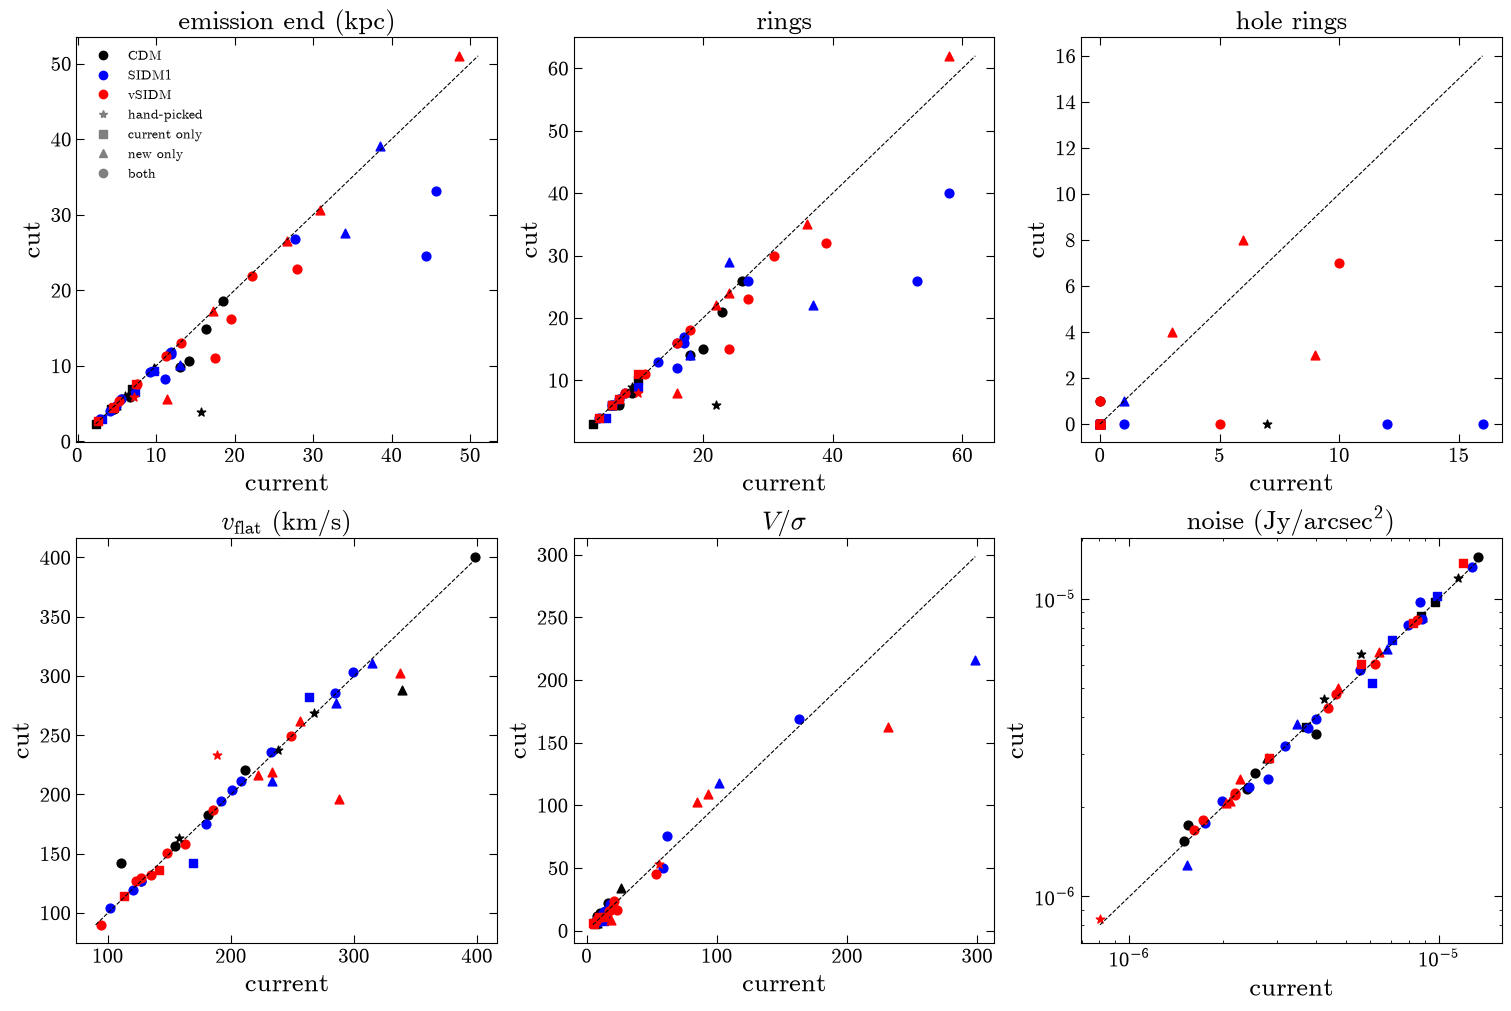

"flat part, cut",False,True
"flat part, current",,
False,6,1
True,2,41


In [4]:
#cut against current cube, per quantity; dashed: equal
quantities = {"emission_end_kpc": "emission end (kpc)", "n_rings": "rings", "hole_rings": "hole rings",
              "v_flat": r"$v_{\rm flat}$ (km/s)", "V_over_sigma": r"$V/\sigma$", "noise_rms": r"noise (Jy/arcsec$^2$)"}
models, groups = wide.index.get_level_values("model"), wide.index.get_level_values("group")
handles = ([Line2D([], [], color=colors[m], marker="o", ls="", label=m) for m in MODELS]
           + [Line2D([], [], color="gray", marker=mk, ls="", label=g) for g, mk in markers.items()])
fig, axes = plt.subplots(2, 3, figsize=(15, 10), constrained_layout=True)
for ax, (q, label) in zip(axes.flat, quantities.items()):
    x, y = wide[(q, "current")].astype(float), wide[(q, "cut")].astype(float)
    for model in MODELS:
        for group, marker in markers.items():
            m = (models == model) & (groups == group)
            ax.scatter(x[m], y[m], color=colors[model], marker=marker, s=40)
    lo, hi = np.nanmin([x.min(), y.min()]), np.nanmax([x.max(), y.max()])
    ax.plot([lo, hi], [lo, hi], color="k", ls="--", lw=0.8)
    if q == "noise_rms":
        ax.set_xscale("log")
        ax.set_yscale("log")
    ax.set_title(label)
    ax.set_xlabel("current")
    ax.set_ylabel("cut")
axes[0, 0].legend(handles=handles, fontsize=10, frameon=False)
plt.show()
pd.crosstab(wide[("flat_rule", "current")].notna(), wide[("flat_rule", "cut")].notna(),
            rownames=["flat part, current"], colnames=["flat part, cut"])

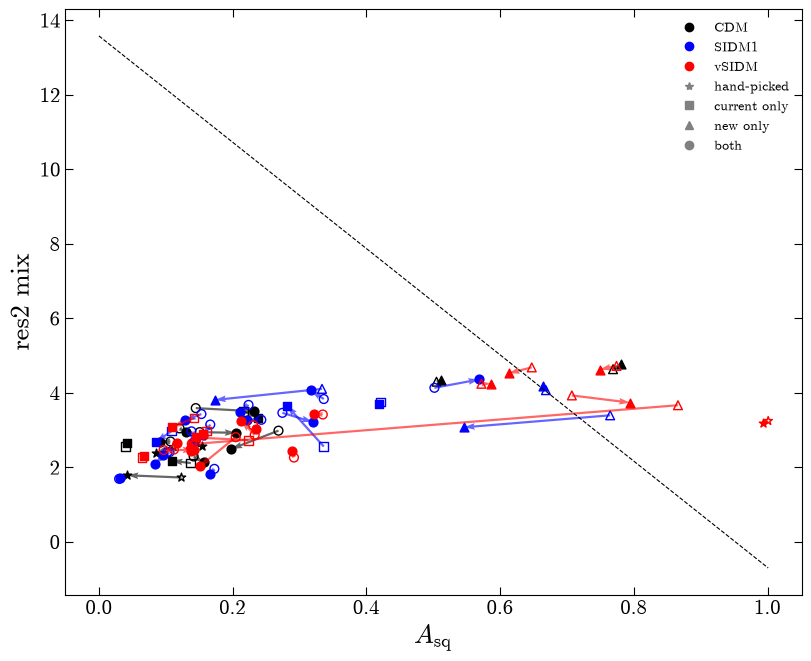

cut                          disc side  perturbed side
group        current                                  
both         disc side              26               0
current only disc side              10               0
hand-picked  disc side               3               0
             perturbed side          0               1
new only     disc side               3               0
             perturbed side          3               4

In [5]:
#(A_sq, mix) plane: hollow current, filled cut, arrow from one to the other; dashed: the current line
fig, ax = plt.subplots(figsize=(8, 6.5), constrained_layout=True)
for model in MODELS:
    for group, marker in markers.items():
        m = (models == model) & (groups == group)
        x0, y0 = wide.loc[m, ("A_sq", "current")].astype(float), wide.loc[m, ("mix", "current")].astype(float)
        x1, y1 = wide.loc[m, ("A_sq", "cut")].astype(float), wide.loc[m, ("mix", "cut")].astype(float)
        ax.scatter(x0, y0, facecolors="none", edgecolors=colors[model], marker=marker, s=40)
        ax.scatter(x1, y1, color=colors[model], marker=marker, s=40)
        ok = (np.isfinite(x0) & np.isfinite(y0) & np.isfinite(x1) & np.isfinite(y1)).to_numpy()
        if ok.any():
            ax.quiver(x0[ok], y0[ok], (x1 - x0)[ok], (y1 - y0)[ok], angles="xy", scale_units="xy", scale=1,
                      color=colors[model], width=0.003, alpha=0.6)
a_sq = np.linspace(0, np.nanmax(wide["A_sq"].to_numpy(dtype=float)), 10)
ax.plot(a_sq, gd.attrs["line_intercept"] + gd.attrs["line_slope"] * a_sq, color="k", ls="--", lw=0.8)
ax.set_xlabel(r"$A_{\rm sq}$")
ax.set_ylabel("res2 mix")
ax.legend(handles=handles, fontsize=10, frameon=False)
plt.show()

side = np.sign(gd["mix"] - gd.attrs["line_intercept"] - gd.attrs["line_slope"] * gd["A_sq"])
pert_side = side[gd["perturbed"]].unique()
if len(pert_side) != 1:
    raise ValueError(f"perturbed galaxies on both sides of the line: {pert_side}")


def line_side(version):
    s = np.sign(wide[("mix", version)].astype(float) - gd.attrs["line_intercept"]
                - gd.attrs["line_slope"] * wide[("A_sq", version)].astype(float))
    return np.where(s.isna(), "not placed", np.where(s == pert_side[0], "perturbed side", "disc side"))


pd.crosstab([groups, line_side("current")], line_side("cut"), rownames=["group", "current"], colnames=["cut"])

In [6]:
#galaxy list for collate_pv.py --mode compare: the selections each galaxy passes and, for current only, the new criteria it fails
def fails_new(r):
    kappa = getattr(r, DISC_RULE["kappa_key"])
    fails = []
    if not kappa >= DISC_RULE["kappa_min"]:
        fails.append(f"{DISC_RULE['kappa_key']} = {kappa:.2f} < {DISC_RULE['kappa_min']:g}")
    if not r.z_cut < DISC_RULE["z_cut_max"]:
        fails.append(f"z_cut = {r.z_cut:.1f} >= {DISC_RULE['z_cut_max']:g} kpc")
    if not r.gas_star_deg <= DISC_RULE["angle_max"]:
        fails.append(f"gas-star angle = {r.gas_star_deg:.1f} > {DISC_RULE['angle_max']:g} deg")
    if not r.warp_deg <= DISC_RULE["angle_max"]:
        fails.append(f"warp angle = {r.warp_deg:.1f} > {DISC_RULE['angle_max']:g} deg")
    if not fails:
        raise ValueError(f"{r.model} z = {r.z:g} {r.subID} fails the new selection on none of its criteria")
    return ", ".join(fails)


passes = np.select([pilot["old_disc"] & pilot["new_rule"], pilot["old_disc"], pilot["new_rule"]],
                   ["both", "current only", "new only"], "neither")
labels = [f"selection: {s}" + (f" // {fails_new(r)}" if s == "current only" else "")
          for r, s in zip(pilot.itertuples(), passes)]
(PILOT / "pilot_pvs.txt").write_text("".join(f"{r.model} {r.z:g} {r.subID} {label}\n"
                                             for r, label in zip(pilot.itertuples(), labels)))
print("\n".join(l for l in labels if "current only" in l))

selection: current only // kappa_co_r95 = 0.69 < 0.8
selection: current only // kappa_co_r95 = 0.53 < 0.8, warp angle = 46.9 > 30 deg
selection: current only // kappa_co_r95 = 0.77 < 0.8
selection: current only // kappa_co_r95 = 0.79 < 0.8
selection: current only // kappa_co_r95 = 0.80 < 0.8
selection: current only // kappa_co_r95 = 0.77 < 0.8, gas-star angle = 123.9 > 30 deg
selection: current only // kappa_co_r95 = 0.62 < 0.8
selection: current only // kappa_co_r95 = 0.68 < 0.8
selection: current only // kappa_co_r95 = 0.65 < 0.8, warp angle = 48.1 > 30 deg
selection: current only // kappa_co_r95 = 0.77 < 0.8
